# Análisis de datos II — Actividad 1

## 1. Librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import shap

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

## 1. Carga del dataset

In [2]:
from pathlib import Path

data_path = ["/mnt/data/ds_salaries.csv"]

if data_path is not None:
    df = pd.read_csv(data_path)
    print(f"Dataset cargado desde: {data_path}")
else:
    DATA_URL = (
        "https://raw.githubusercontent.com/gaju45/"
        "EDA-on-data-science-salary-dataset/master/ds_salaries.csv"
    )
    df = pd.read_csv(DATA_URL)
    print("Dataset cargado desde el espejo público de GitHub.")

print("Shape:", df.shape)
display(df.head())

Dataset cargado desde: /mnt/data/ds_salaries.csv
Shape: (3755, 11)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


## 2. EDA

In [3]:
print("Tipos de datos:")
display(df.dtypes.to_frame("dtype"))

print("\nValores faltantes:")
display(df.isna().sum().to_frame("n_missing"))

print("\nCantidad de valores únicos:")
display(df.nunique().sort_values(ascending=False).to_frame("n_unique"))

n_duplicates = df.duplicated().sum()
print(f"\nFilas duplicadas exactas: {n_duplicates}")
print(f"Porcentaje de duplicados: {100*n_duplicates/len(df):.2f}%")

Tipos de datos:


,dtype
work_year,int64
experience_level,object
employment_type,object
job_title,object
salary,int64
salary_currency,object
salary_in_usd,int64
employee_residence,object
remote_ratio,int64
company_location,object



Valores faltantes:


,n_missing
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0



Cantidad de valores únicos:


,n_unique
salary_in_usd,1035
salary,815
job_title,93
employee_residence,78
company_location,72
salary_currency,20
work_year,4
employment_type,4
experience_level,4
remote_ratio,3



Filas duplicadas exactas: 1171
Porcentaje de duplicados: 31.19%


### Variable objetivo

In [4]:
target = "salary_in_usd"

X = df.drop(columns=target)
y = df[target]

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

print("Variables categóricas:")
print(categorical_features)

print("\nVariables numéricas:")
print(numeric_features)

Variables categóricas:
['experience_level', 'employment_type', 'job_title', 'salary_currency', 'employee_residence', 'company_location', 'company_size']

Variables numéricas:
['work_year', 'salary', 'remote_ratio']


## 3. Entrenamiento — Random Forest 

Las variables categóricas se transforman mediante **One-Hot Encoding**, mientras que las numéricas pasan sin modificación.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Compatibilidad con distintas versiones de scikit-learn
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", encoder, categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
feature_names_clean = [
    name.replace("cat__", "").replace("num__", "")
    for name in feature_names
]

print("Shape train original:", X_train.shape)
print("Shape train transformado:", X_train_trans.shape)

Shape train original: (3004, 10)
Shape train transformado: (3004, 260)


In [6]:
model = RandomForestRegressor(random_state=RANDOM_STATE)
model.fit(X_train_trans, y_train)

y_pred_train = model.predict(X_train_trans)
y_pred = model.predict(X_test_trans)

### Evaluación del modelo]

In [7]:
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred)
mae_test = mean_absolute_error(y_test, y_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))

metrics_original = {
    "R2_train": r2_train,
    "R2_test": r2_test,
    "MAE": mae_test,
    "RMSE": rmse_test
}

print(f"R² train: {r2_train:.4f}")
print(f"R² test : {r2_test:.4f}")
print(f"MAE     : USD {mae_test:,.2f}")
print(f"RMSE    : USD {rmse_test:,.2f}")

R² train: 0.9942
R² test : 0.9832
MAE     : USD 1,248.34
RMSE    : USD 8,148.56


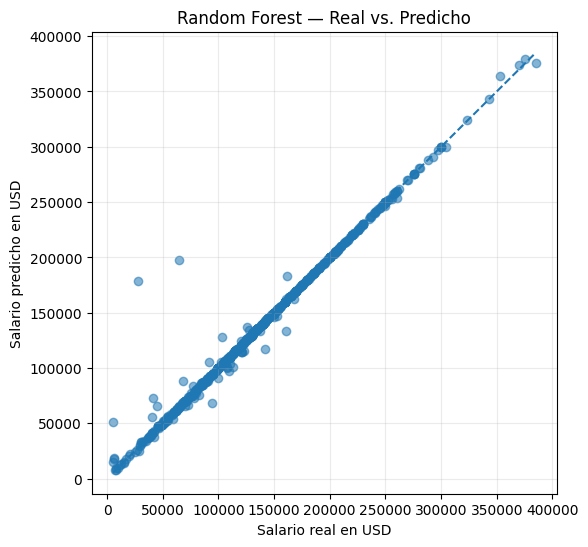

In [8]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.55)

lim_min = min(y_test.min(), y_pred.min())
lim_max = max(y_test.max(), y_pred.max())

plt.plot([lim_min, lim_max], [lim_min, lim_max], linestyle="--")
plt.xlabel("Salario real en USD")
plt.ylabel("Salario predicho en USD")
plt.title("Random Forest — Real vs. Predicho")
plt.grid(alpha=0.25)
plt.show()

### Interpretación: 

La calidad del modelo inicial debe interpretarse con cautela. Un R² elevado **no garantiza que el modelo haya aprendido relaciones legítimas**. En esta actividad, precisamente, utilizaremos técnicas de interpretabilidad para investigar si el desempeño puede estar artificialmente favorecido por variables que contienen información directa o casi directa sobre el target.

# 5. Diagnóstico global — Permutation Feature Importance (PFI)

In [9]:
model_pfi = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

result = permutation_importance(
    model_pfi,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1
)

pfi = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean,
    "std": result.importances_std
}).sort_values("importance", ascending=False)

display(pfi)

,feature,importance,std
4,salary,1.912932,0.080445
5,salary_currency,0.441808,0.033266
6,employee_residence,0.001038,0.000072
8,company_location,0.000902,0.000197
0,work_year,0.000412,0.000089
3,job_title,0.000369,0.000447
9,company_size,0.000342,0.000375
1,experience_level,0.000108,0.000177
2,employment_type,0.000064,0.000058
7,remote_ratio,-0.000063,0.000519


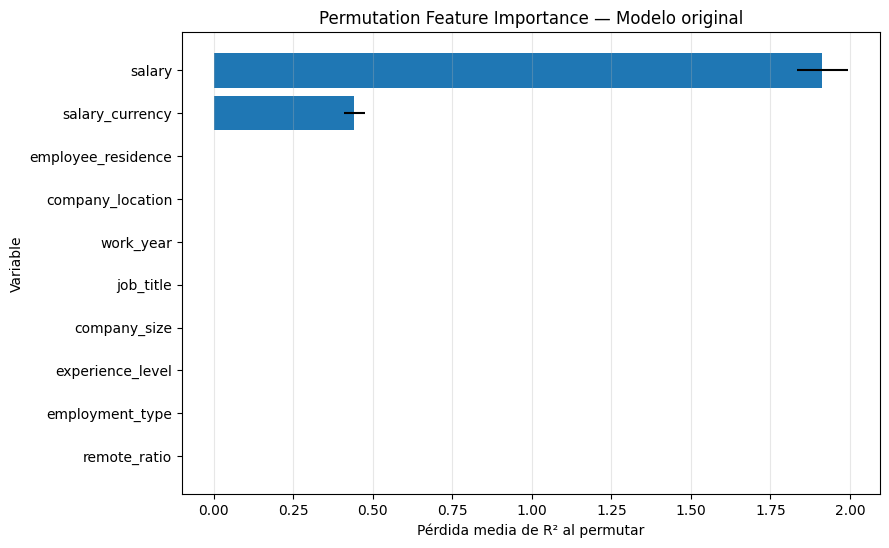

In [10]:
plt.figure(figsize=(9, 6))
plt.barh(
    pfi["feature"],
    pfi["importance"],
    xerr=pfi["std"]
)

plt.xlabel("Pérdida media de R² al permutar")
plt.ylabel("Variable")
plt.title("Permutation Feature Importance — Modelo original")
plt.grid(axis="x", alpha=0.3)
plt.gca().invert_yaxis()
plt.show()

In [11]:
top_global = pfi.head(5).copy()

print("Variables más importantes según PFI:")
for _, row in top_global.iterrows():
    print(
        f"- {row['feature']}: "
        f"importancia={row['importance']:.4f} ± {row['std']:.4f}"
    )

dominant = pfi.iloc[0]
if dominant["importance"] > 2 * max(pfi.iloc[1]["importance"], 1e-12):
    print(
        f"\nATENCIÓN: '{dominant['feature']}' presenta una importancia "
        "muy superior a la del resto. Esto merece auditoría."
    )

Variables más importantes según PFI:
- salary: importancia=1.9129 ± 0.0804
- salary_currency: importancia=0.4418 ± 0.0333
- employee_residence: importancia=0.0010 ± 0.0001
- company_location: importancia=0.0009 ± 0.0002
- work_year: importancia=0.0004 ± 0.0001

ATENCIÓN: 'salary' presenta una importancia muy superior a la del resto. Esto merece auditoría.


### Interpretación de PFI

El resultado es llamativo: `salary` obtiene una importancia PFI de **1.9129**, muy por encima de `salary_currency` (**0.4418**) y del resto de las variables, cuyas importancias son cercanas a cero. Esto indica que el modelo depende casi por completo de la información salarial original para sostener su R².

Este patrón requiere auditoría porque `salary_in_usd` es una conversión de `salary` a dólares. Por lo tanto, el excelente desempeño inicial puede no reflejar capacidad real para predecir salarios a partir de características laborales, sino la reconstrucción de una variable derivada.

### ¿Qué resultados llaman la atención?

En este dataset existe una razón conceptual para sospechar especialmente de `salary`: `salary_in_usd` es el salario convertido a dólares, mientras que `salary` es el salario antes de la conversión y `salary_currency` identifica su moneda. Por lo tanto, si estas variables dominan PFI, no deberíamos interpretar ese resultado como un descubrimiento económico sobre los salarios, sino como una posible señal de **target leakage**.

# 5. Diagnóstico local — SHAP

In [12]:
explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test_trans)
base_value = float(np.asarray(explainer.expected_value).reshape(-1)[0])

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.repeat(base_value, X_test_trans.shape[0]),
    data=X_test_trans,
    feature_names=feature_names_clean
)

print("Shape de SHAP values:", explanation.values.shape)
print(f"Valor base aproximado: USD {base_value:,.2f}")

Shape de SHAP values: (751, 260)
Valor base aproximado: USD 137,991.30


## 6.1 Selección de dos observaciones

In [13]:
i_high = int(np.argmax(y_pred))
i_low = int(np.argmin(y_pred))

selected_cases = pd.DataFrame({
    "caso": ["Predicción alta", "Predicción baja"],
    "posicion_en_test": [i_high, i_low],
    "indice_original": [X_test.index[i_high], X_test.index[i_low]],
    "valor_real": [y_test.iloc[i_high], y_test.iloc[i_low]],
    "prediccion": [y_pred[i_high], y_pred[i_low]],
    "error_absoluto": [
        abs(y_test.iloc[i_high] - y_pred[i_high]),
        abs(y_test.iloc[i_low] - y_pred[i_low])
    ]
})

display(selected_cases)

,caso,posicion_en_test,indice_original,valor_real,prediccion,error_absoluto
0,Predicción alta,513,2359,375000,379113.61,4113.61
1,Predicción baja,538,573,7000,7697.22,697.22


OBSERVACIÓN CON PREDICCIÓN ALTA


,work_year,experience_level,employment_type,job_title,salary,salary_currency,employee_residence,remote_ratio,company_location,company_size
2359,2022,SE,FT,Data Science Tech Lead,375000,USD,US,50,US,L


Real      : USD 375,000.00
Predicción: USD 379,113.61
Error abs.: USD 4,113.61


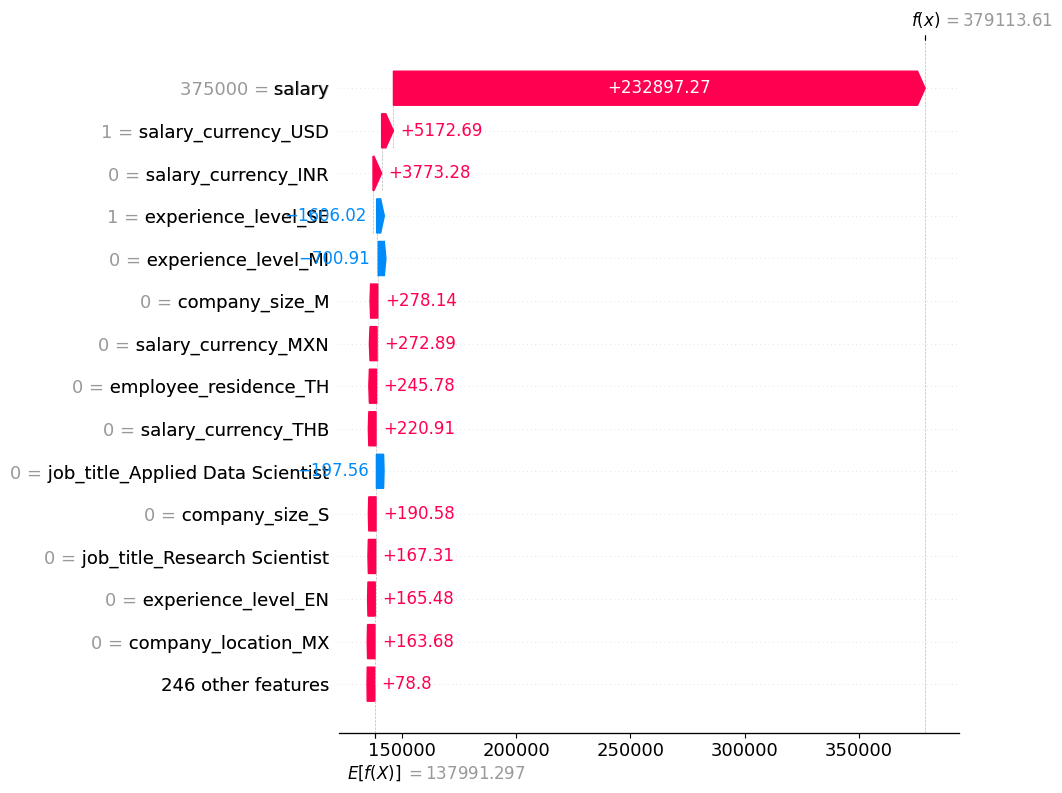

In [14]:
print("OBSERVACIÓN CON PREDICCIÓN ALTA")
display(X_test.iloc[[i_high]])
print(f"Real      : USD {y_test.iloc[i_high]:,.2f}")
print(f"Predicción: USD {y_pred[i_high]:,.2f}")
print(f"Error abs.: USD {abs(y_test.iloc[i_high]-y_pred[i_high]):,.2f}")

shap.plots.waterfall(explanation[i_high], max_display=15)

OBSERVACIÓN CON PREDICCIÓN BAJA


,work_year,experience_level,employment_type,job_title,salary,salary_currency,employee_residence,remote_ratio,company_location,company_size
573,2023,EN,FT,Autonomous Vehicle Technician,7000,USD,GH,0,GH,S


Real      : USD 7,000.00
Predicción: USD 7,697.22
Error abs.: USD 697.22


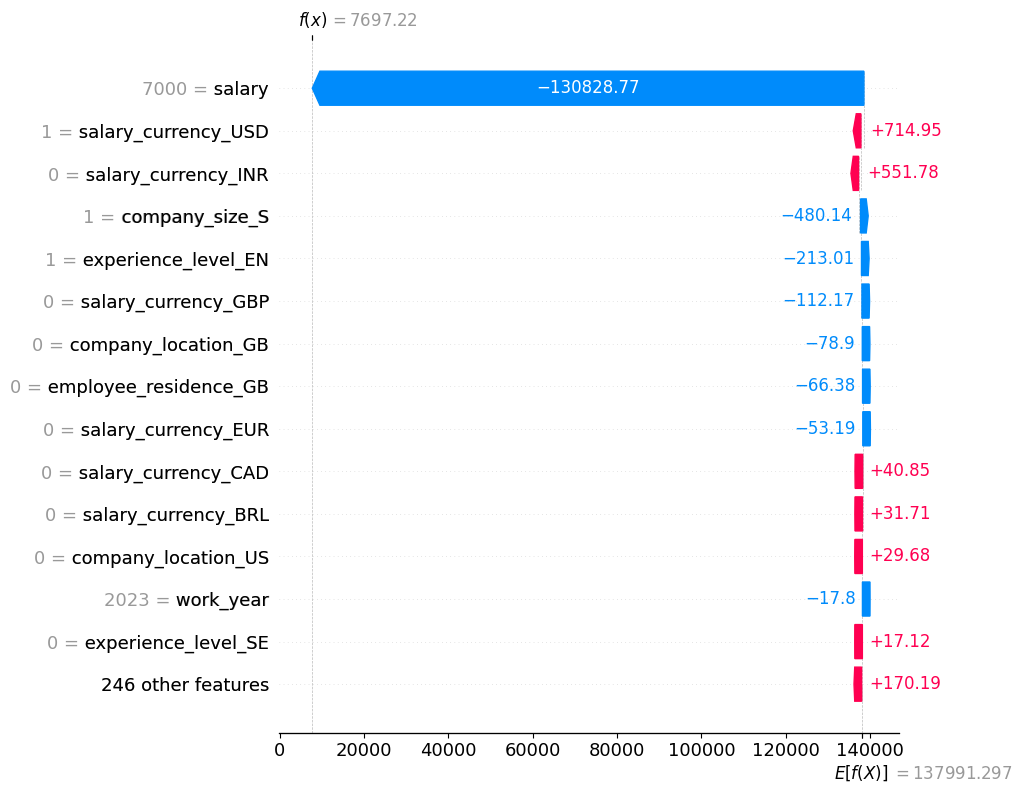

In [15]:
print("OBSERVACIÓN CON PREDICCIÓN BAJA")
display(X_test.iloc[[i_low]])
print(f"Real      : USD {y_test.iloc[i_low]:,.2f}")
print(f"Predicción: USD {y_pred[i_low]:,.2f}")
print(f"Error abs.: USD {abs(y_test.iloc[i_low]-y_pred[i_low]):,.2f}")

shap.plots.waterfall(explanation[i_low], max_display=15)

### Agregación de SHAP por variable original

In [16]:
def original_feature_from_transformed(transformed_name, categorical_cols):
    clean = transformed_name.replace("cat__", "").replace("num__", "")

    if transformed_name.startswith("num__"):
        return clean

    for col in categorical_cols:
        if clean.startswith(col + "_"):
            return col

    return clean


original_feature_map = [
    original_feature_from_transformed(name, categorical_features)
    for name in feature_names
]


def aggregate_local_shap(i):
    tmp = pd.DataFrame({
        "feature_transformada": feature_names_clean,
        "feature_original": original_feature_map,
        "shap_value": explanation.values[i]
    })

    agg = (
        tmp.groupby("feature_original", as_index=False)["shap_value"]
        .sum()
    )
    agg["abs_shap"] = agg["shap_value"].abs()
    agg["direccion"] = np.where(
        agg["shap_value"] >= 0,
        "Aumenta la predicción",
        "Disminuye la predicción"
    )
    return agg.sort_values("abs_shap", ascending=False)


shap_high = aggregate_local_shap(i_high)
shap_low = aggregate_local_shap(i_low)

print("Top contribuciones — predicción alta")
display(shap_high.head(10))

print("\nTop contribuciones — predicción baja")
display(shap_low.head(10))

Top contribuciones — predicción alta


,feature_original,shap_value,abs_shap,direccion
7,salary,232897.271611,232897.271611,Aumenta la predicción
8,salary_currency,9521.519384,9521.519384,Aumenta la predicción
4,experience_level,-2154.137530,2154.137530,Disminuye la predicción
1,company_size,533.260631,533.260631,Aumenta la predicción
2,employee_residence,200.724737,200.724737,Aumenta la predicción
0,company_location,179.536700,179.536700,Aumenta la predicción
5,job_title,-167.013493,167.013493,Disminuye la predicción
9,work_year,136.773394,136.773394,Aumenta la predicción
6,remote_ratio,-98.529030,98.529030,Disminuye la predicción
3,employment_type,72.906188,72.906188,Aumenta la predicción



Top contribuciones — predicción baja


,feature_original,shap_value,abs_shap,direccion
7,salary,-130828.765565,130828.765565,Disminuye la predicción
8,salary_currency,1215.942838,1215.942838,Aumenta la predicción
1,company_size,-484.955078,484.955078,Disminuye la predicción
4,experience_level,-206.980805,206.980805,Disminuye la predicción
9,work_year,-17.799983,17.799983,Disminuye la predicción
2,employee_residence,15.135044,15.135044,Aumenta la predicción
5,job_title,12.598286,12.598286,Aumenta la predicción
3,employment_type,11.111376,11.111376,Aumenta la predicción
6,remote_ratio,-10.365946,10.365946,Disminuye la predicción
0,company_location,0.002427,0.002427,Aumenta la predicción


In [17]:
def print_local_interpretation(label, i, table):
    print(f"\n{label}")
    print(f"Valor real : USD {y_test.iloc[i]:,.2f}")
    print(f"Predicción : USD {y_pred[i]:,.2f}")
    print(f"Valor base : USD {base_value:,.2f}")
    print("\nVariables con mayor contribución absoluta:")

    for _, row in table.head(5).iterrows():
        sign = "+" if row["shap_value"] >= 0 else "-"
        print(
            f"- {row['feature_original']}: "
            f"{sign}USD {abs(row['shap_value']):,.2f} "
            f"({row['direccion']})"
        )


print_local_interpretation(
    "CASO 1 — PREDICCIÓN ALTA",
    i_high,
    shap_high
)

print_local_interpretation(
    "CASO 2 — PREDICCIÓN BAJA",
    i_low,
    shap_low
)


CASO 1 — PREDICCIÓN ALTA
Valor real : USD 375,000.00
Predicción : USD 379,113.61
Valor base : USD 137,991.30

Variables con mayor contribución absoluta:
- salary: +USD 232,897.27 (Aumenta la predicción)
- salary_currency: +USD 9,521.52 (Aumenta la predicción)
- experience_level: -USD 2,154.14 (Disminuye la predicción)
- company_size: +USD 533.26 (Aumenta la predicción)
- employee_residence: +USD 200.72 (Aumenta la predicción)

CASO 2 — PREDICCIÓN BAJA
Valor real : USD 7,000.00
Predicción : USD 7,697.22
Valor base : USD 137,991.30

Variables con mayor contribución absoluta:
- salary: -USD 130,828.77 (Disminuye la predicción)
- salary_currency: +USD 1,215.94 (Aumenta la predicción)
- company_size: -USD 484.96 (Disminuye la predicción)
- experience_level: -USD 206.98 (Disminuye la predicción)
- work_year: -USD 17.80 (Disminuye la predicción)


### Interpretación de los dos casos SHAP

**Caso de predicción alta.** El modelo parte de un valor base de aproximadamente **USD 137,991** y llega a una predicción de **USD 379,114**. La contribución dominante es `salary`, con aproximadamente **+USD 232,897**, seguida por `salary_currency` con **+USD 9,522**. El resto de las variables tiene un impacto mucho menor. Esto es coherente con PFI: global y localmente el modelo está utilizando principalmente la información salarial original.

**Caso de predicción baja.** Desde el mismo valor base, `salary` aporta aproximadamente **−USD 130,829**, llevando la predicción hacia **USD 7,697**. Nuevamente, `salary` domina ampliamente la explicación, mientras que `salary_currency` aporta cerca de **+USD 1,216** y el resto tiene contribuciones pequeñas.

Por lo tanto, las explicaciones locales son **coherentes con el diagnóstico global**: la variable de mayor importancia según PFI es también la que explica casi por completo las dos predicciones individuales seleccionadas. Esta coherencia, refuerza la evidencia de leakage.

## 6.2 Coherencia entre SHAP local y PFI global

In [18]:
top_global_set = set(pfi.head(5)["feature"])

top_high_set = set(shap_high.head(5)["feature_original"])
top_low_set = set(shap_low.head(5)["feature_original"])

print("Top 5 globales:", sorted(top_global_set))
print("Coincidencias con caso alto:", sorted(top_global_set & top_high_set))
print("Coincidencias con caso bajo:", sorted(top_global_set & top_low_set))

Top 5 globales: ['company_location', 'employee_residence', 'salary', 'salary_currency', 'work_year']
Coincidencias con caso alto: ['employee_residence', 'salary', 'salary_currency']
Coincidencias con caso bajo: ['salary', 'salary_currency', 'work_year']


# 7. Auditoría del modelo

## Hallazgo 1 — Posible data leakage por `salary`

### Evidencia

Según la definición de las variables:

- `salary` = salario bruto en la moneda original;
- `salary_currency` = moneda;
- `salary_in_usd` = ese salario expresado en USD.

Por lo tanto, el target se obtiene conceptualmente a partir de información ya presente en `salary` y `salary_currency` —y el año puede intervenir en el tipo de cambio—. Si el objetivo real fuera predecir un salario USD **antes de conocer el salario pactado**, `salary` no estaría disponible en inferencia.

A continuación se cuantifica esta relación.

In [19]:
audit_df = df.copy()

usd_mask = audit_df["salary_currency"].eq("USD")

print(f"Observaciones con moneda USD: {usd_mask.sum()} de {len(audit_df)}")
print(f"Porcentaje USD: {100*usd_mask.mean():.2f}%")

if usd_mask.any():
    same_usd = (
        audit_df.loc[usd_mask, "salary"]
        == audit_df.loc[usd_mask, "salary_in_usd"]
    ).mean()
    print(
        "Entre las filas en USD, salary == salary_in_usd en "
        f"{100*same_usd:.2f}% de los casos."
    )

audit_df["conversion_ratio"] = (
    audit_df["salary_in_usd"] / audit_df["salary"]
)

fx_table = (
    audit_df.groupby(["work_year", "salary_currency"])["conversion_ratio"]
    .agg(n="size", media="mean", std="std", minimo="min", maximo="max")
    .reset_index()
)

fx_table["rango_relativo"] = (
    (fx_table["maximo"] - fx_table["minimo"])
    / fx_table["media"].replace(0, np.nan)
)

display(
    fx_table
    .sort_values(["n", "rango_relativo"], ascending=[False, True])
    .head(20)
)

Observaciones con moneda USD: 3224 de 3755
Porcentaje USD: 85.86%
Entre las filas en USD, salary == salary_in_usd en 100.00% de los casos.


,work_year,salary_currency,n,media,std,minimo,maximo,rango_relativo
47,2023,USD,1646,1.000000,0.000000e+00,1.000000,1.000000,0.000000
34,2022,USD,1418,1.000000,0.000000e+00,1.000000,1.000000,0.000000
22,2021,USD,122,1.000000,0.000000e+00,1.000000,1.000000,0.000000
28,2022,EUR,115,1.050662,5.002365e-06,1.050650,1.050669,0.000018
29,2022,GBP,83,1.231328,5.564395e-06,1.231314,1.231334,0.000016
40,2023,GBP,62,1.215226,6.183916e-06,1.215211,1.215233,0.000019
39,2023,EUR,53,1.073085,6.328765e-06,1.073050,1.073092,0.000039
14,2021,EUR,44,1.182046,1.459011e-05,1.181963,1.182058,0.000080
8,2020,USD,38,1.000000,0.000000e+00,1.000000,1.000000,0.000000
2,2020,EUR,24,1.140463,1.035608e-05,1.140429,1.140474,0.000040


### Interpretación 

**¿Es razonable?**  
No como variable predictora en un escenario donde queremos estimar el salario antes de que éste sea conocido. El modelo puede aprovechar una transformación casi directa del target en lugar de aprender relaciones generalizables entre experiencia, puesto, localización y remuneración.

**Posible causa:** la base contiene simultáneamente el salario original y su conversión a USD porque fue diseñada para análisis descriptivo, no necesariamente para un problema predictivo.

**Acción:** eliminar `salary` y `salary_currency` del conjunto de predictores y volver a entrenar.

## Hallazgo 2 — Filas duplicadas y contaminación potencial entre train/test


In [20]:
train_full = X_train.copy()
train_full[target] = y_train

test_full = X_test.copy()
test_full[target] = y_test

all_cols = df.columns.tolist()

test_rows_seen_in_train = test_full.merge(
    train_full.drop_duplicates(),
    on=all_cols,
    how="inner"
)

print(f"Duplicados exactos en todo el dataset: {df.duplicated().sum()}")
print(
    "Filas del test que tienen una copia exacta en train: "
    f"{len(test_rows_seen_in_train)} de {len(test_full)} "
    f"({100*len(test_rows_seen_in_train)/len(test_full):.2f}%)"
)

Duplicados exactos en todo el dataset: 1171
Filas del test que tienen una copia exacta en train: 307 de 751 (40.88%)


### Interpretación

La salida anterior cuantifica tanto los duplicados globales como las observaciones de test que poseen una copia exacta en entrenamiento.

**¿Es razonable?**  
Los duplicados pueden ser registros válidos —dos personas con exactamente las mismas características—, pero para una evaluación predictiva conviene evitar que una misma fila exacta aparezca a ambos lados del split.

**Posible causa:** agregación/recolección de ofertas repetidas o registros replicados.

**Acción:** realizar `drop_duplicates()` antes del split y comparar nuevamente.

## Hallazgo 3 — Posible redundancia entre residencia del empleado y localización de la empresa

`employee_residence` y `company_location` son conceptualmente diferentes, pero en muchos casos pueden coincidir. Si están altamente asociadas, PFI puede repartir la importancia entre ambas: permutar una sola no destruye toda la información geográfica porque la otra conserva parte de la señal.

In [21]:
same_location = (
    df["employee_residence"] == df["company_location"]
)

print(
    "employee_residence == company_location: "
    f"{100*same_location.mean():.2f}% de las observaciones"
)

location_pair_counts = (
    df.groupby(["employee_residence", "company_location"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

display(location_pair_counts.to_frame("n"))

employee_residence == company_location: 97.44% de las observaciones


,,n
employee_residence,company_location,
US,US,2999
GB,GB,166
CA,CA,83
ES,ES,75
IN,IN,56
DE,DE,46
FR,FR,32
BR,BR,15
GR,GR,14


### Interpretación y acción

**Evidencia:** alto porcentaje de coincidencia entre ambas columnas, junto con el patrón observado en PFI.

**¿Es razonable?**  
Sí: muchos trabajadores residen en el mismo país donde se encuentra la empresa.

**Posible causa:** ambas variables capturan una señal geográfica/económica similar.

**Acción:** no eliminar automáticamente ninguna. Primero se puede comparar el modelo con una de ellas removida, agrupar regiones o usar importancia condicional. La redundancia hace que una PFI individual baja no deba interpretarse como “la geografía no importa”.

## Hallazgo 4 — Variables categóricas de alta cardinalidad

`job_title`, `employee_residence` y `company_location` pueden generar muchas dummies. Las categorías poco frecuentes son especialmente susceptibles a estimaciones inestables y a reglas específicas de pocos registros.

In [22]:
categorical_audit = []

for col in categorical_features:
    counts = df[col].value_counts()
    categorical_audit.append({
        "feature": col,
        "n_categorias": counts.size,
        "categorias_con_menos_de_5": int((counts < 5).sum()),
        "frecuencia_minima": int(counts.min()),
        "frecuencia_maxima": int(counts.max())
    })

categorical_audit = pd.DataFrame(categorical_audit).sort_values(
    "n_categorias",
    ascending=False
)

display(categorical_audit)

,feature,n_categorias,categorias_con_menos_de_5,frecuencia_minima,frecuencia_maxima
2,job_title,93,44,1,1040
4,employee_residence,78,53,1,3004
5,company_location,72,51,1,3040
3,salary_currency,20,11,1,3224
0,experience_level,4,0,114,2516
1,employment_type,4,0,10,3718
6,company_size,3,0,148,3153


### Interpretación y acción

No constituye leakage por sí mismo, pero sí puede hacer que el modelo sea menos estable para puestos o países raros.

Una acción razonable sería agrupar categorías infrecuentes en `"Other"` o utilizar técnicas de validación que permitan comprobar estabilidad. No se aplica aquí para no convertir la actividad en un ejercicio de optimización.

# 8. Corrección del leakage y reentrenamiento

In [23]:
def make_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def train_rf_on_split(X_train_, X_test_, y_train_, y_test_):
    cat_cols = X_train_.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    num_cols = X_train_.select_dtypes(
        exclude=["object", "category"]
    ).columns.tolist()

    prep = ColumnTransformer(
        transformers=[
            ("cat", make_encoder(), cat_cols),
            ("num", "passthrough", num_cols)
        ]
    )

    Xtr = prep.fit_transform(X_train_)
    Xte = prep.transform(X_test_)

    rf = RandomForestRegressor(random_state=RANDOM_STATE)
    rf.fit(Xtr, y_train_)

    pred_train = rf.predict(Xtr)
    pred_test = rf.predict(Xte)

    metrics = {
        "R2_train": r2_score(y_train_, pred_train),
        "R2_test": r2_score(y_test_, pred_test),
        "MAE": mean_absolute_error(y_test_, pred_test),
        "RMSE": np.sqrt(mean_squared_error(y_test_, pred_test))
    }

    pipe = Pipeline([
        ("preprocessor", prep),
        ("model", rf)
    ])

    return {
        "preprocessor": prep,
        "model": rf,
        "pipeline": pipe,
        "pred_train": pred_train,
        "pred_test": pred_test,
        "metrics": metrics,
        "cat_cols": cat_cols,
        "num_cols": num_cols
    }

In [24]:
# Dataset sin duplicados
df_unique = df.drop_duplicates().copy()

X_unique_all = df_unique.drop(columns=target)
y_unique = df_unique[target]

# Un único split para comparar de manera directa:
# modelo con y sin las variables de leakage.
idx_train, idx_test = train_test_split(
    np.arange(len(df_unique)),
    test_size=0.20,
    random_state=RANDOM_STATE
)

X_u_train_all = X_unique_all.iloc[idx_train]
X_u_test_all = X_unique_all.iloc[idx_test]
y_u_train = y_unique.iloc[idx_train]
y_u_test = y_unique.iloc[idx_test]

model_unique_all = train_rf_on_split(
    X_u_train_all,
    X_u_test_all,
    y_u_train,
    y_u_test
)

# Modelo final sin leakage
leakage_features = ["salary", "salary_currency"]

X_unique_final = X_unique_all.drop(columns=leakage_features)

X_f_train = X_unique_final.iloc[idx_train]
X_f_test = X_unique_final.iloc[idx_test]

model_final = train_rf_on_split(
    X_f_train,
    X_f_test,
    y_u_train,
    y_u_test
)

In [25]:
comparison = pd.DataFrame([
    {
        "modelo": "Original: datos crudos + todas las variables",
        **metrics_original
    },
    {
        "modelo": "Sin duplicados + todas las variables",
        **model_unique_all["metrics"]
    },
    {
        "modelo": "Final: sin duplicados + sin salary/salary_currency",
        **model_final["metrics"]
    }
])

display(
    comparison.style.format({
        "R2_train": "{:.4f}",
        "R2_test": "{:.4f}",
        "MAE": "USD {:,.2f}",
        "RMSE": "USD {:,.2f}"
    })
)

,modelo,R2_train,R2_test,MAE,RMSE
0,Original: datos crudos + todas las variables,0.9942,0.9832,"USD 1,248.34","USD 8,148.56"
1,Sin duplicados + todas las variables,0.9943,0.9479,"USD 2,146.49","USD 15,090.55"
2,Final: sin duplicados + sin salary/salary_currency,0.6460,0.3676,"USD 38,577.26","USD 52,594.71"


### Resultado real de la comparación

El modelo original alcanza **R² test = 0.9832**, pero ese resultado está favorecido por dos problemas detectados durante la auditoría. Primero, el dataset contiene **1,171 filas duplicadas (31.19%)** y, con el split aleatorio original, **307 de 751 observaciones de test (40.88%)** poseen una copia exacta en train. Segundo, `salary` permite reconstruir casi directamente `salary_in_usd`.

Al eliminar únicamente los duplicados, el R² test baja de **0.9832 a 0.9479**, mientras que el RMSE aumenta de aproximadamente **USD 8,149 a USD 15,091**. Esto muestra que los duplicados estaban haciendo la evaluación más optimista.

Al eliminar además `salary` y `salary_currency`, el R² test cae a **0.3676** y el RMSE aumenta a aproximadamente **USD 52,595**. Aunque el desempeño numérico es menor, el comportamiento del modelo es metodológicamente más defendible porque ya no tiene acceso a una representación casi directa de la variable objetivo.

## Interpretación de la comparación

Es esperable que el modelo final pierda desempeño al eliminar `salary` y `salary_currency`. Esa caída **no implica que el modelo corregido sea peor desde el punto de vista metodológico**: significa que dejamos de darle información que prácticamente revela el target.

# 9. PFI del modelo final sin leakage

In [26]:
pfi_final_result = permutation_importance(
    model_final["pipeline"],
    X_f_test,
    y_u_test,
    scoring="r2",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1
)

pfi_final = pd.DataFrame({
    "feature": X_f_test.columns,
    "importance": pfi_final_result.importances_mean,
    "std": pfi_final_result.importances_std
}).sort_values("importance", ascending=False)

display(pfi_final)

,feature,importance,std
4,employee_residence,0.354124,0.053258
1,experience_level,0.201367,0.034798
3,job_title,0.094782,0.014207
5,remote_ratio,0.012985,0.005033
0,work_year,0.012282,0.018436
6,company_location,0.007237,0.004305
2,employment_type,0.001607,0.003806
7,company_size,-0.007993,0.008801


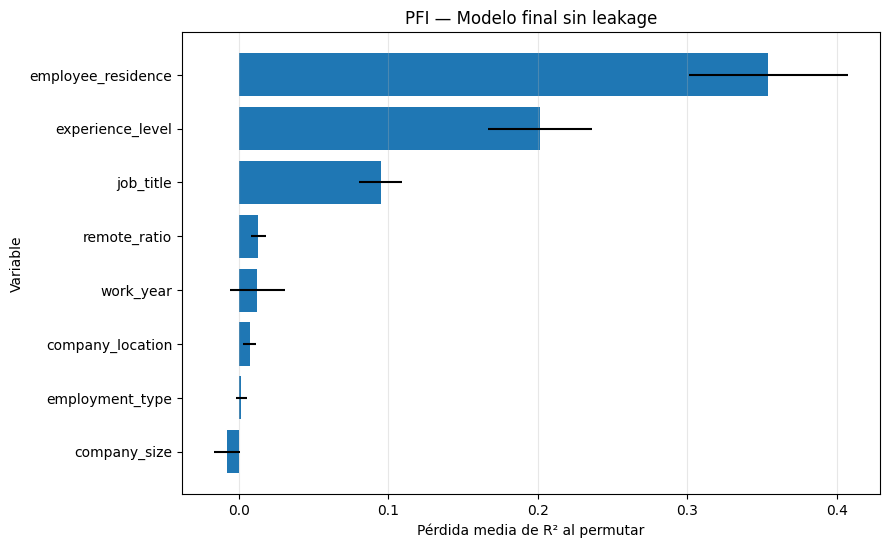

In [27]:
plt.figure(figsize=(9, 6))
plt.barh(
    pfi_final["feature"],
    pfi_final["importance"],
    xerr=pfi_final["std"]
)

plt.xlabel("Pérdida media de R² al permutar")
plt.ylabel("Variable")
plt.title("PFI — Modelo final sin leakage")
plt.grid(axis="x", alpha=0.3)
plt.gca().invert_yaxis()
plt.show()

In [28]:
print("Top 5 PFI — modelo original")
display(pfi.head(5))

print("\nTop 5 PFI — modelo final")
display(pfi_final.head(5))

Top 5 PFI — modelo original


,feature,importance,std
4,salary,1.912932,0.080445
5,salary_currency,0.441808,0.033266
6,employee_residence,0.001038,0.000072
8,company_location,0.000902,0.000197
0,work_year,0.000412,0.000089



Top 5 PFI — modelo final


,feature,importance,std
4,employee_residence,0.354124,0.053258
1,experience_level,0.201367,0.034798
3,job_title,0.094782,0.014207
5,remote_ratio,0.012985,0.005033
0,work_year,0.012282,0.018436


### Cambio de importancia después de corregir el leakage

Una vez eliminadas las variables problemáticas, la importancia se redistribuye hacia variables más razonables para explicar salarios:

- `employee_residence`: **0.3541**
- `experience_level`: **0.2014**
- `job_title`: **0.0948**
- `remote_ratio`: **0.0130**
- `work_year`: **0.0123**

Este ranking es mucho más interpretable desde el dominio: residencia, experiencia y puesto pueden estar asociados a diferencias salariales. Además, `company_location` tiene una importancia individual baja, pero esto debe interpretarse considerando que `employee_residence` y `company_location` coinciden en **97.44%** de las observaciones, por lo que existe una redundancia geográfica muy fuerte y PFI puede repartir la señal entre ambas.

# 10. Conclusiones finales de la auditoría

El análisis muestra que el **Random Forest original parece excelente en métricas, pero no es confiable como modelo predictivo** sin una auditoría de las variables.

**Leakage.** El modelo original obtuvo **R² test = 0.9832**, MAE ≈ **USD 1,248** y RMSE ≈ **USD 8,149**. Sin embargo, PFI reveló que `salary` domina la predicción con una importancia de **1.9129**, seguida por `salary_currency` con **0.4418**. SHAP confirmó el mismo patrón a nivel local: en la predicción alta, `salary` aportó aproximadamente **+USD 232,897**, y en la predicción baja aportó aproximadamente **−USD 130,829**. Dado que `salary_in_usd` se construye a partir del salario original y su moneda, esta señal se interpreta como **data leakage**.

**Duplicados.** El dataset posee **1,171 filas duplicadas**, equivalentes al **31.19%** de los registros. Además, en el split original, **40.88% del test** tenía una copia exacta en train. Al quitar duplicados, el R² test disminuyó de **0.9832 a 0.9479**, confirmando que la evaluación inicial estaba parcialmente favorecida por repetición de información.

**Redundancia.** `employee_residence` y `company_location` coinciden en **97.44%** de los casos. Esto significa que ambas variables contienen información geográfica muy similar y que una PFI individual pequeña para una de ellas no implica necesariamente que la información geográfica sea irrelevante.

**Modelo corregido.** Tras eliminar duplicados y las variables `salary` y `salary_currency`, el R² test fue **0.3676**, MAE ≈ **USD 38,577** y RMSE ≈ **USD 52,595**. La caída es grande, pero esperable: el modelo deja de utilizar información que prácticamente revela el target. En el modelo corregido, las principales variables según PFI pasan a ser `employee_residence` (**0.3541**), `experience_level` (**0.2014**) y `job_title` (**0.0948**), un comportamiento sustancialmente más razonable.

En conclusión, las técnicas de interpretabilidad no sólo ayudaron a explicar las predicciones, sino que permitieron detectar que el gran desempeño inicial era **engañoso**.